# 02 · Person A — Lesion segmentation + optic disc / fovea localization
Trains two small models from the IDRiD **A. Segmentation** and **C. Localization** zips (already in `data/raw_upload/`).
Runtime ▸ **T4 GPU**. Total time ≈ 15 min. Outputs: `models/seg_unet.pth`, `models/loc_resnet.pth` (+ metrics for the app's About tab).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, glob, json, shutil, zipfile
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt

PROJECT_PATH = '/content/drive/MyDrive/DR_Project'
MODELS_DIR = f'{PROJECT_PATH}/models'
sys.path.append(f'{PROJECT_PATH}/app')          # shared code lives in app/dr_core.py
from dr_core import *

for f in ['data/aptos', 'data/idrid', 'data/processed', 'data/processed_idrid', 'data/raw_upload',
          'models', 'outputs/gradcam_samples', 'app/samples', 'notebooks']:
    os.makedirs(f'{PROJECT_PATH}/{f}', exist_ok=True)
RAW = f'{PROJECT_PATH}/data/raw_upload'
print('raw_upload contains:', os.listdir(RAW))
import torch, torch.nn as nn
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)
def norm_batch(x):                        # uint8 NHWC -> normalised float NCHW
    return torch.from_numpy(np.ascontiguousarray(((x.astype(np.float32) / 255 - MEAN) / STD).transpose(0, 3, 1, 2)))

Mounted at /content/drive
raw_upload contains: ['aptos2019-blindness-detection.zip', 'idrid.zip']
device: cuda


## Part 1 — Lesion segmentation (MA · HE · EX · SE · optic disc)

In [4]:
# Extract main idrid.zip if we haven't already
idrid_zip = f'{RAW}/idrid.zip'
if os.path.exists(idrid_zip) and not glob.glob(f'{RAW}/**/*segmentation*.zip', recursive=True):
    print('Extracting main idrid.zip to search for nested datasets...')
    with zipfile.ZipFile(idrid_zip) as z:
        z.extractall(RAW)

# Search recursively for a segmentation zip file
seg_zips = [p for p in glob.glob(f'{RAW}/**/*.zip', recursive=True) if 'segmentation' in p.lower()]

if seg_zips:
    seg_zip = seg_zips[0]
    print(f'Found segmentation zip: {seg_zip}. Extracting...')
    with zipfile.ZipFile(seg_zip) as z:
        z.extractall('/content/seg_temp')
else:
    # If it was already extracted as a directory instead of a nested zip
    seg_dirs = [p for p in glob.glob(f'{RAW}/**/', recursive=True) if 'segmentation' in p.lower()]
    if seg_dirs:
        print(f'Found extracted segmentation folder: {seg_dirs[0]}')
        shutil.copytree(seg_dirs[0], '/content/seg_temp', dirs_exist_ok=True)
    else:
        raise FileNotFoundError('Could not find any segmentation zip files or extracted folders.')

imgs = sorted(glob.glob('/content/seg_temp/**/*.jpg', recursive=True))
masks = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob('/content/seg_temp/**/*.tif', recursive=True)}
tr = [p for p in imgs if 'train' in p.lower()]; te = [p for p in imgs if 'test' in p.lower()]
print(len(tr), 'train /', len(te), 'test images (expect 54 / 27);', len(masks), 'mask files'); print(list(masks)[:5])

Extracting main idrid.zip to search for nested datasets...
Found extracted segmentation folder: /content/drive/MyDrive/DR_Project/data/raw_upload/IDRiD_dataset/A. Segmentation/
54 train / 27 test images (expect 54 / 27); 363 mask files
['IDRiD_28_MA', 'IDRiD_13_MA', 'IDRiD_09_MA', 'IDRiD_39_MA', 'IDRiD_30_MA']


In [5]:
def load_pair(p):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    x = prep_image(img, SEG_SIZE)
    stem = os.path.splitext(os.path.basename(p))[0]
    y = np.zeros((5, SEG_SIZE, SEG_SIZE), np.uint8)
    for i, suf in enumerate(LESION_SUFFIX):
        mp = masks.get(f'{stem}_{suf}')
        if mp is None: continue                               # not every image has every lesion type
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if m is None: continue
        m = cv2.resize(((m > 0) * 255).astype(np.uint8), (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA)
        y[i] = m >= (8 if suf == 'MA' else 127)               # keep tiny microaneurysms alive after downscaling
    return x, y

Xtr, Ytr = map(np.stack, zip(*[load_pair(p) for p in tr]))
Xte, Yte = map(np.stack, zip(*[load_pair(p) for p in te]))
print(Xtr.shape, Ytr.shape)
print('images containing each lesion (train):', dict(zip(LESIONS, (Ytr.sum((2, 3)) > 0).sum(0))))

(54, 512, 512, 3) (54, 5, 512, 512)
images containing each lesion (train): {'Microaneurysms': np.int64(54), 'Haemorrhages': np.int64(53), 'Hard exudates': np.int64(54), 'Soft exudates': np.int64(26), 'Optic disc': np.int64(54)}


In [6]:
def batches(X, Y, bs, aug):
    idx = np.random.permutation(len(X)) if aug else np.arange(len(X))
    for i in range(0, len(idx), bs):
        b = idx[i:i + bs]; x, y = X[b].copy(), Y[b].copy()
        if aug:
            for j in range(len(b)):
                if np.random.rand() < .5: x[j] = np.ascontiguousarray(x[j][:, ::-1]); y[j] = np.ascontiguousarray(y[j][:, :, ::-1])
                if np.random.rand() < .5: x[j] = np.ascontiguousarray(x[j][::-1]);    y[j] = np.ascontiguousarray(y[j][:, ::-1])
                if np.random.rand() < .5: x[j] = np.ascontiguousarray(x[j].transpose(1, 0, 2)); y[j] = np.ascontiguousarray(y[j].transpose(0, 2, 1))
        yield norm_batch(x), torch.from_numpy(y.astype(np.float32))

pos_w = torch.tensor([10., 5., 5., 5., 1.]).view(1, 5, 1, 1).to(dev)
bce = nn.BCEWithLogitsLoss(pos_weight=pos_w)
def dice_loss(logits, y):
    p = torch.sigmoid(logits); inter = (p * y).sum((2, 3)); den = p.sum((2, 3)) + y.sum((2, 3))
    present = (y.sum((2, 3)) > 0).float()
    return (((1 - (2 * inter + 1) / (den + 1)) * present).sum() / present.sum().clamp(min=1))

@torch.no_grad()
def eval_dice(model, thr=0.5):
    model.eval(); inter = np.zeros(5); den = np.zeros(5)
    for x, y in batches(Xte, Yte, 3, False):
        p = (torch.sigmoid(model(x.to(dev))) > thr).float().cpu()
        inter += (p * y).sum((0, 2, 3)).numpy(); den += (p.sum((0, 2, 3)) + y.sum((0, 2, 3))).numpy()
    return np.where(den > 0, 2 * inter / np.maximum(den, 1), np.nan)

In [7]:
EPOCHS = 60
seg = UNetResNet18(5, pretrained=True).to(dev)
opt = torch.optim.AdamW(seg.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
use_amp = dev == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
best = -1
for ep in range(1, EPOCHS + 1):
    seg.train(); tot = 0
    for x, y in batches(Xtr, Ytr, 4, True):
        x, y = x.to(dev), y.to(dev)
        with torch.amp.autocast('cuda', enabled=use_amp):
            out = seg(x)
        loss = bce(out.float(), y) + dice_loss(out.float(), y)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
    sched.step()
    if ep % 5 == 0 or ep == EPOCHS:
        d = eval_dice(seg); m = np.nanmean(d)
        print(f'epoch {ep:2d}  loss {tot:6.2f}  dice ' + ' '.join(f'{n[:3]}={v:.2f}' for n, v in zip(LESIONS, d)) + f'  mean={m:.3f}')
        if m > best:
            best = m; save_half(seg, f'{MODELS_DIR}/{SEG_FILE}'); print('   saved best')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


epoch  5  loss  20.61  dice Mic=0.00 Hae=0.14 Har=0.25 Sof=0.00 Opt=0.79  mean=0.236
   saved best
epoch 10  loss  19.03  dice Mic=0.05 Hae=0.28 Har=0.30 Sof=0.03 Opt=0.90  mean=0.311
   saved best
epoch 15  loss  17.75  dice Mic=0.06 Hae=0.31 Har=0.41 Sof=0.38 Opt=0.88  mean=0.409
   saved best
epoch 20  loss  16.71  dice Mic=0.09 Hae=0.37 Har=0.59 Sof=0.51 Opt=0.91  mean=0.493
   saved best
epoch 25  loss  15.89  dice Mic=0.17 Hae=0.44 Har=0.59 Sof=0.45 Opt=0.94  mean=0.517
   saved best
epoch 30  loss  15.25  dice Mic=0.22 Hae=0.53 Har=0.62 Sof=0.56 Opt=0.93  mean=0.573
   saved best
epoch 35  loss  14.77  dice Mic=0.26 Hae=0.50 Har=0.59 Sof=0.61 Opt=0.93  mean=0.579
   saved best
epoch 40  loss  14.44  dice Mic=0.26 Hae=0.51 Har=0.60 Sof=0.56 Opt=0.94  mean=0.572
epoch 45  loss  14.22  dice Mic=0.27 Hae=0.52 Har=0.64 Sof=0.58 Opt=0.94  mean=0.589
   saved best
epoch 50  loss  14.09  dice Mic=0.27 Hae=0.52 Har=0.64 Sof=0.58 Opt=0.95  mean=0.593
   saved best
epoch 55  loss  14.04  d

Final dice: {'Microaneurysms': np.float64(0.272), 'Haemorrhages': np.float64(0.519), 'Hard exudates': np.float64(0.643), 'Soft exudates': np.float64(0.581), 'Optic disc': np.float64(0.948)}


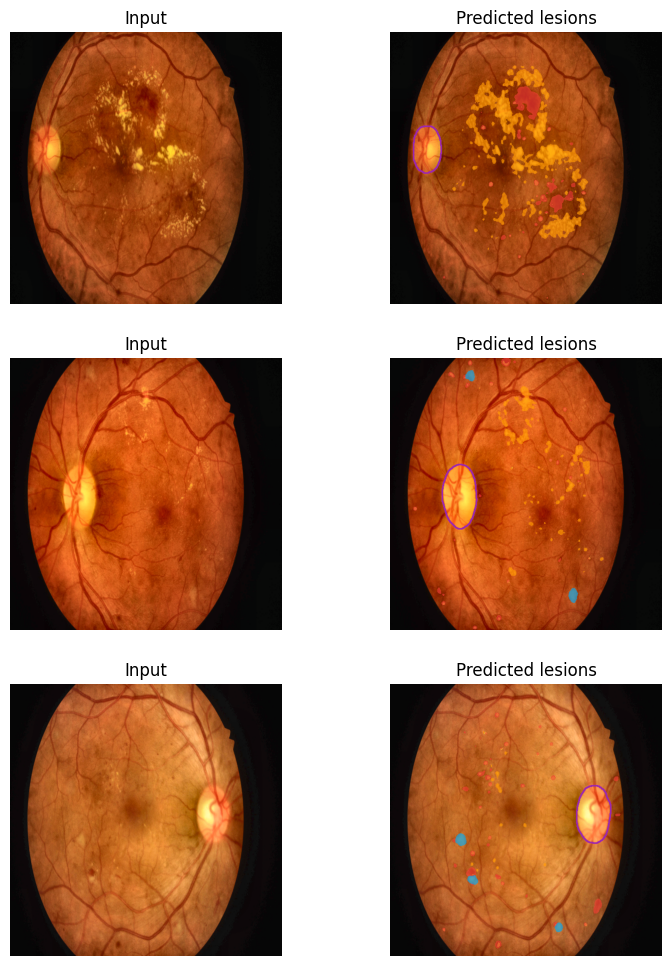

In [8]:
seg = load_weights(UNetResNet18(5), f'{MODELS_DIR}/{SEG_FILE}').to(dev)
d = eval_dice(seg)
update_metrics(MODELS_DIR, 'segmentation', {'dice_per_class': {n: (None if np.isnan(v) else round(float(v), 3)) for n, v in zip(LESIONS, d)},
                                           'mean_dice': round(float(np.nanmean(d)), 3), 'train_images': len(tr), 'test_images': len(te)})
print('Final dice:', dict(zip(LESIONS, np.round(d, 3))))

# qualitative figure for the report
fig, ax = plt.subplots(3, 2, figsize=(9, 12))
for r, i in enumerate([0, 9, 18]):
    x, _ = next(batches(Xte[i:i + 1], Yte[i:i + 1], 1, False))
    with torch.no_grad(): p = torch.sigmoid(seg(x.to(dev)))[0].cpu().numpy()
    ov, _ = lesion_overlay(Xte[i], p, 0.5)
    ax[r, 0].imshow(Xte[i]); ax[r, 0].set_title('Input'); ax[r, 1].imshow(ov); ax[r, 1].set_title('Predicted lesions')
    ax[r, 0].axis('off'); ax[r, 1].axis('off')
plt.savefig(f'{PROJECT_PATH}/outputs/seg_examples.png', bbox_inches='tight'); plt.show()

> **Expect:** hard exudates and optic disc score best, microaneurysms worst (tiny lesions, only 54 training images). That's normal — say so in your report.

## Part 2 — Optic disc + fovea localization

In [10]:
# Search recursively for a localization zip file
loc_zips = [p for p in glob.glob(f'{RAW}/**/*.zip', recursive=True) if 'locali' in p.lower()]

if loc_zips:
    loc_zip = loc_zips[0]
    print(f'Found localization zip: {loc_zip}. Extracting...')
    with zipfile.ZipFile(loc_zip) as z:
        z.extractall('/content/loc_temp')
else:
    # Find the extracted folder containing 'localization' or 'C. ' inside RAW
    loc_dirs = [p for p in glob.glob(f'{RAW}/**/', recursive=True) if 'locali' in p.lower() or 'c. ' in p.lower()]
    if loc_dirs:
        print(f'Found extracted localization folder: {loc_dirs[0]}')
        shutil.copytree(loc_dirs[0], '/content/loc_temp', dirs_exist_ok=True)
    else:
        raise FileNotFoundError('Could not find any localization zip files or extracted folders.')

limgs = glob.glob('/content/loc_temp/**/*.jpg', recursive=True)
csvs = glob.glob('/content/loc_temp/**/*.csv', recursive=True)
path_of = {os.path.splitext(os.path.basename(p))[0]: p for p in limgs}
print(len(limgs), 'images (expect 516);', [os.path.basename(c) for c in csvs])

def read_points(key):
    rows = []
    for f in csvs:
        if key in os.path.basename(f).lower().replace(' ', ''):
            d = pd.read_csv(f); d.columns = [c.strip() for c in d.columns]; d = d.dropna(how='all')
            xc = [c for c in d.columns if c.lower().replace(' ', '').startswith('x')][0]
            yc = [c for c in d.columns if c.lower().replace(' ', '').startswith('y')][0]
            rows.append(pd.DataFrame({'id': d[d.columns[0]].astype(str).str.strip().str.replace('.jpg', '', regex=False),
                                      key + '_x': pd.to_numeric(d[xc], errors='coerce'), key + '_y': pd.to_numeric(d[yc], errors='coerce')}))
    return pd.concat(rows)
pts = read_points('od_center').merge(read_points('fovea'), on='id').dropna()
print(len(pts), 'images with both landmarks'); pts.head()

Found extracted localization folder: /content/drive/MyDrive/DR_Project/data/raw_upload/IDRiD_dataset/C. Localization/
516 images (expect 516); ['b. IDRiD_OD_Center_Testing Set_Markups.csv', 'a. IDRiD_OD_Center_Training Set_Markups.csv', 'IDRiD_Fovea_Center_Training Set_Markups.csv', 'IDRiD_Fovea_Center_Testing Set_Markups.csv']
722 images with both landmarks


,id,od_center_x,od_center_y,fovea_x,fovea_y
0,IDRiD_001,651.0,1453.0,1494.0,1970.0
1,IDRiD_001,651.0,1453.0,1914.0,1617.0
2,IDRiD_002,3158.0,1280.0,2270.0,1329.0
3,IDRiD_002,3158.0,1280.0,1922.0,1468.0
4,IDRiD_003,1101.0,1374.0,2109.0,1351.0


In [11]:
def load_loc(row):
    img = cv2.cvtColor(cv2.imread(path_of[row.id]), cv2.COLOR_BGR2RGB); h, w = img.shape[:2]
    t = np.array([row.od_center_x / w, row.od_center_y / h, row.fovea_x / w, row.fovea_y / h], np.float32)
    return prep_image(img, LOC_SIZE), t, (w, h)

data = [load_loc(r) for r in pts.itertuples()]
is_tr = np.array(['train' in path_of[i].lower() for i in pts['id']])
XL = np.stack([d[0] for d in data]); TL = np.stack([d[1] for d in data]); WH = np.array([d[2] for d in data], np.float32)
Xl_tr, Tl_tr, Xl_te, Tl_te, WH_te = XL[is_tr], TL[is_tr], XL[~is_tr], TL[~is_tr], WH[~is_tr]
print(Xl_tr.shape, Xl_te.shape, 'target range', Tl_tr.min().round(2), Tl_tr.max().round(2))

(310, 256, 256, 3) (412, 256, 256, 3) target range 0.12 0.8


In [12]:
LE = 40
loc = build_localizer(pretrained=True).to(dev)
opt = torch.optim.AdamW(loc.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, LE)
l1 = nn.L1Loss()

@torch.no_grad()
def loc_predict(model, X):
    model.eval(); out = []
    for i in range(0, len(X), 32): out.append(model(norm_batch(X[i:i + 32]).to(dev)).cpu().numpy())
    return np.concatenate(out)
def pixel_errors(P, T, wh):
    od = np.hypot((P[:, 0] - T[:, 0]) * wh[:, 0], (P[:, 1] - T[:, 1]) * wh[:, 1])
    fv = np.hypot((P[:, 2] - T[:, 2]) * wh[:, 0], (P[:, 3] - T[:, 3]) * wh[:, 1])
    return od, fv

best = 1e9
for ep in range(1, LE + 1):
    loc.train(); perm = np.random.permutation(len(Xl_tr)); tot = 0
    for i in range(0, len(perm), 16):
        b = perm[i:i + 16]; x = Xl_tr[b].copy(); t = Tl_tr[b].copy()
        flip = np.random.rand(len(b)) < .5
        x[flip] = x[flip][:, :, ::-1]; t[flip, 0] = 1 - t[flip, 0]; t[flip, 2] = 1 - t[flip, 2]      # horizontal flip
        x = np.clip(x.astype(np.float32) * np.random.uniform(.85, 1.15, (len(b), 1, 1, 1)), 0, 255).astype(np.uint8)
        loss = l1(loc(norm_batch(x).to(dev)), torch.from_numpy(t).to(dev))
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
    sched.step()
    if ep % 5 == 0:
        od, fv = pixel_errors(loc_predict(loc, Xl_te), Tl_te, WH_te); m = (od.mean() + fv.mean()) / 2
        print(f'epoch {ep:2d} loss {tot:.3f}  mean error: OD {od.mean():.0f}px  fovea {fv.mean():.0f}px')
        if m < best: best = m; save_half(loc, f'{MODELS_DIR}/{LOC_FILE}'); print('   saved best')

epoch  5 loss 0.678  mean error: OD 658px  fovea 324px
   saved best
epoch 10 loss 0.786  mean error: OD 908px  fovea 389px
epoch 15 loss 0.590  mean error: OD 696px  fovea 280px
   saved best
epoch 20 loss 0.390  mean error: OD 728px  fovea 269px
epoch 25 loss 0.369  mean error: OD 660px  fovea 308px
   saved best
epoch 30 loss 0.313  mean error: OD 651px  fovea 254px
   saved best
epoch 35 loss 0.230  mean error: OD 631px  fovea 254px
   saved best
epoch 40 loss 0.205  mean error: OD 635px  fovea 253px


{'od_mean_error_px': 631.2, 'od_median_error_px': 97.3, 'fovea_mean_error_px': 254.5, 'fovea_median_error_px': 139.3, 'image_width_px': 4288, 'test_images': 412}


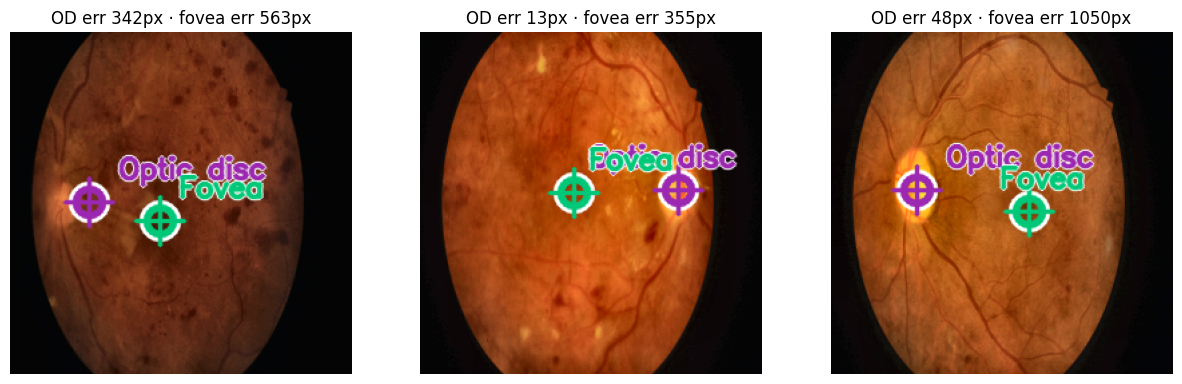

In [13]:
loc = load_weights(build_localizer(), f'{MODELS_DIR}/{LOC_FILE}').to(dev)
P = loc_predict(loc, Xl_te); od, fv = pixel_errors(P, Tl_te, WH_te)
res = {'od_mean_error_px': round(float(od.mean()), 1), 'od_median_error_px': round(float(np.median(od)), 1),
       'fovea_mean_error_px': round(float(fv.mean()), 1), 'fovea_median_error_px': round(float(np.median(fv)), 1),
       'image_width_px': int(WH_te[:, 0].mean()), 'test_images': int(len(Xl_te))}
update_metrics(MODELS_DIR, 'localization', res); print(res)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, i in zip(ax, [0, 30, 60]):
    a.imshow(draw_landmarks(Xl_te[i], P[i])); a.set_title(f'OD err {od[i]:.0f}px · fovea err {fv[i]:.0f}px'); a.axis('off')
plt.savefig(f'{PROJECT_PATH}/outputs/loc_examples.png', bbox_inches='tight'); plt.show()

### ✅ Done → tell the team
> "Segmentation + localization models are in `models/` (`seg_unet.pth`, `loc_resnet.pth`). Metrics are in `models/metrics.json`; figures in `outputs/`."

You can now **delete `data/raw_upload/`** in Drive (and empty the trash) to free several GB — your desktop copies are the backup.